# Semantic Embeddings and Clustering

Goal: find out whether **semantic** representations improve theme discovery compared with **lexical** TF-IDF features.

TF-IDF treats *lecturer*, *teacher* and *professor* as unrelated words. A sentence-embedding model maps each comment to a dense vector so that comments with similar *meaning* end up close together, even when they share no words.

Two clustering pipelines:
- **Approach A**: embeddings → PCA → KMeans
- **Approach B**: embeddings → UMAP → HDBSCAN

Explored: embedding models, PCA dimensions, UMAP `n_neighbors` and dimensions, HDBSCAN minimum cluster size, random seeds.

Measured: silhouette score, cluster sizes, noise (unassigned) percentage, interpretability, and stability across parameter and seed changes.

Input: `data/processed/cleaned_feedback.csv`. Outputs are written to `results/`.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import umap
from sentence_transformers import SentenceTransformer
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_score

RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

# Two harmless library warnings: a seeded UMAP runs single-threaded, and HDBSCAN's `copy` default will change.
warnings.filterwarnings("ignore", message="n_jobs value")
warnings.filterwarnings("ignore", message="The default value of `copy`")

/home/riccha/Documents/practice-agentic-ai/student-feedback-intelligence/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the data

All 724 comments, including duplicates. Clustering has no train/test split, and the duplicates (*"good"*, *"excellent"*) are real responses that a production system will keep receiving.

In [2]:
df = pd.read_csv("../data/processed/cleaned_feedback.csv")
texts = df["text"].tolist()
len(df)

724

## 2. Sentence embeddings

Two SentenceTransformer models:
- `all-MiniLM-L6-v2`: small and fast, 384 dimensions
- `all-mpnet-base-v2`: larger and usually more accurate, 768 dimensions

The first run downloads the models (~90 MB and ~420 MB).

`normalize_embeddings=True` scales every vector to length 1. Then the dot product of two vectors is their cosine similarity, and KMeans' Euclidean distance behaves like cosine distance.

In [3]:
MODEL_NAMES = ["all-MiniLM-L6-v2", "all-mpnet-base-v2"]

models = {name: SentenceTransformer(name) for name in MODEL_NAMES}
embeddings = {name: model.encode(texts, normalize_embeddings=True) for name, model in models.items()}

{name: e.shape for name, e in embeddings.items()}

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4002.43it/s]


{'all-MiniLM-L6-v2': (724, 384), 'all-mpnet-base-v2': (724, 768)}

What does "semantic similarity" mean in practice? Embed a query and find the most similar comments. Look for matches that share **no words** with the query, which TF-IDF could not find.

In [4]:
query = models["all-MiniLM-L6-v2"].encode(["the lecturer explains concepts clearly"], normalize_embeddings=True)
df.assign(similarity=embeddings["all-MiniLM-L6-v2"] @ query[0]).nlargest(10, "similarity")[["text", "category", "similarity"]]

,text,category,similarity
245,Lectures helps in clear our concept,teaching,0.653090
633,everything is good but when coming to some lec...,teaching,0.579645
634,lecturer are punctual and can interact them ea...,teaching,0.572501
24,All lectures are giving their best to teach th...,teaching,0.552213
41,Everything is fine. Every thing is taught in d...,course_content,0.538494
495,"good, teacher is delivery the lecture in the b...",teaching,0.511227
99,With the help of practicals students are able ...,labwork,0.498495
244,everything was good regarding to university bu...,teaching,0.495102
107,Excellent lectures are delivered by teachers a...,teaching,0.492725
457,the content of the course is knowledgeable,course_content,0.486392


## 3. How we evaluate a clustering

Every clustering below is scored the same way:
- **n_clusters**, and **largest_cluster_pct**: a single huge cluster is the catch-all failure seen with TF-IDF on Day 2
- **noise_pct**: share of comments HDBSCAN leaves unassigned (label −1). KMeans always assigns everything, so it's 0 there
- **silhouette**: cohesion vs separation, always computed in the **full embedding space** with cosine distance, noise excluded. Computing it in the reduced PCA/UMAP space would reward the reduction itself: UMAP in particular packs points into tight blobs, which inflates silhouette
- **ari_vs_category**: Adjusted Rand Index between clusters and the existing categories. 1 = same grouping, 0 = no better than random. It's not a target (clusters may find better themes than the labels), but it shows whether clusters follow topic at all
- **ari_vs_sentiment**: the same against sentiment. If this is higher than ARI vs category, the clusters group comments by tone rather than topic

In [5]:
def evaluate(labels, emb):
    clustered = labels != -1
    n_clusters = len(set(labels[clustered]))
    return {
        "n_clusters": n_clusters,
        "largest_cluster_pct": round(100 * pd.Series(labels[clustered]).value_counts(normalize=True).max(), 1),
        "noise_pct": round(100 * (~clustered).mean(), 1),
        "silhouette": silhouette_score(emb[clustered], labels[clustered], metric="cosine") if n_clusters > 1 else None,
        "ari_vs_category": adjusted_rand_score(df["category"], labels),
        "ari_vs_sentiment": adjusted_rand_score(df["sentiment"], labels),
    }

## 4. Choosing the embedding model

KMeans with k = 6 (the number of categories) directly on each model's embeddings. Silhouette scores from different embedding spaces aren't directly comparable, so focus on cluster sizes and the ARI columns.

In [6]:
model_rows = []
for name, emb in embeddings.items():
    labels = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(emb)
    model_rows.append({"method": "KMeans", "params": f"model={name}, k=6", **evaluate(labels, emb)})

pd.DataFrame(model_rows).round(3)

,method,params,n_clusters,largest_cluster_pct,noise_pct,silhouette,ari_vs_category,ari_vs_sentiment
0,KMeans,"model=all-MiniLM-L6-v2, k=6",6,23.2,0.0,0.146,0.201,0.044
1,KMeans,"model=all-mpnet-base-v2, k=6",6,31.4,0.0,0.126,0.189,0.022


**Reading the results**

- **Cluster sizes**: with k = 6, a perfectly even split would put 16.7% of comments in each cluster. MiniLM's largest cluster holds 23.2% and mpnet's holds 31.4%, so mpnet puts about a third of the comments into one cluster that will probably be a mixed catch-all. On Day 2, TF-IDF had the same problem in a much worse form.
- **ari_vs_category**: 0.201 (MiniLM) vs 0.189 (mpnet). Both are well above 0 (random), so the clusters partly follow topic, but both are far from 1. The gap of 0.012 is small: this is one KMeans seed, and a different seed could reverse the order. Treat the two models as about equal on this metric.
- **ari_vs_sentiment**: 0.044 and 0.022 are close to 0. Neither model groups comments by tone, which is what we want for theme discovery. It's expected, because sentence embeddings mostly capture *what* a comment is about.
- **silhouette**: 0.146 vs 0.126. These come from different embedding spaces (384 vs 768 dimensions), so don't use them to choose a model. Both are low, which means the clusters overlap. That's normal for short feedback, where many comments are generic ("good", "average") or mention more than one topic.

**Conclusion**: the larger model brings no benefit on this data. MiniLM is as good or slightly better on every comparable metric, gives less of a catch-all cluster, and is several times faster. Short comments of a few words give mpnet's extra capacity little to work with.

The rest of the notebook uses one model. Prefer the one with the higher `ari_vs_category` and the smaller largest cluster. If the two are close, take the smaller model: it is several times faster to run on new comments. Change `MODEL` to compare.

In [7]:
MODEL = "all-MiniLM-L6-v2"
E = embeddings[MODEL]

## 5. Baseline for comparison: TF-IDF → KMeans

The Day 2 clustering, scored with the same metrics. Silhouette is computed in the embedding space for every method, so TF-IDF clusters are judged by how semantically coherent they are.

In [8]:
tfidf = TfidfVectorizer(stop_words="english", min_df=2).fit_transform(texts)
tfidf_labels = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(tfidf)

baseline_rows = [{"method": "TF-IDF+KMeans", "params": "k=6", **evaluate(tfidf_labels, E)}]
pd.DataFrame(baseline_rows).round(3)

,method,params,n_clusters,largest_cluster_pct,noise_pct,silhouette,ari_vs_category,ari_vs_sentiment
0,TF-IDF+KMeans,k=6,6,66.9,0.0,0.007,0.034,-0.057


## 6. Approach A: embeddings → PCA → KMeans

**PCA** (principal component analysis) finds the directions along which the embeddings vary most and keeps the top *d* of them. It's linear, fast, and can project new comments with `transform`.

How many dimensions are needed? The curve shows how much of the total variance the first *d* components keep.

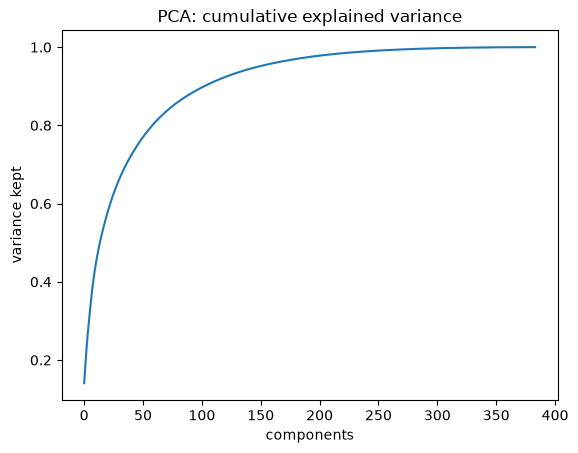

In [9]:
pca_full = PCA(random_state=42).fit(E)
pd.Series(pca_full.explained_variance_ratio_.cumsum()).plot(
    title="PCA: cumulative explained variance", xlabel="components", ylabel="variance kept"
)
plt.show()

**Result:** the curve rises slowly: 10 components keep only about 43% of the variance and 80% needs about 59, so the meaning in these embeddings is spread across many directions rather than concentrated in a few.

### 6a. PCA dimensions

Reduce to *d* dimensions, then KMeans with k = 6.

In [10]:
pca_rows = []
for d in [2, 5, 10, 25, 50, 100]:
    reduced = PCA(n_components=d, random_state=42).fit_transform(E)
    labels = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(reduced)
    pca_rows.append({"method": "PCA+KMeans", "params": f"pca={d}, k=6", **evaluate(labels, E)})

pd.DataFrame(pca_rows).round(3)

,method,params,n_clusters,largest_cluster_pct,noise_pct,silhouette,ari_vs_category,ari_vs_sentiment
0,PCA+KMeans,"pca=2, k=6",6,19.6,0.0,0.076,0.101,0.031
1,PCA+KMeans,"pca=5, k=6",6,30.0,0.0,0.176,0.194,0.046
2,PCA+KMeans,"pca=10, k=6",6,30.9,0.0,0.175,0.186,0.042
3,PCA+KMeans,"pca=25, k=6",6,30.7,0.0,0.177,0.188,0.046
4,PCA+KMeans,"pca=50, k=6",6,30.7,0.0,0.175,0.186,0.044
5,PCA+KMeans,"pca=100, k=6",6,30.7,0.0,0.175,0.187,0.044


**Result:** 2 dimensions are too few (silhouette 0.076, ARI 0.101), but from 5 up to 100 the metrics barely change, so KMeans only uses structure that the first few components already hold, even though those components keep under half the variance.

### 6b. Stability across random seeds

Both steps can be random: on data this size sklearn's PCA uses a randomized solver, and KMeans picks random starting centres. Fix PCA with `random_state=42` (as everywhere in this notebook) so only the KMeans seed changes. Run KMeans with 5 seeds and compare each result with seed 0 using ARI. ARI = 1 means exactly the same clusters.

In [11]:
PCA_DIM = 10
reduced = PCA(n_components=PCA_DIM, random_state=42).fit_transform(E)
seed_labels = [KMeans(n_clusters=6, n_init=10, random_state=seed).fit_predict(reduced) for seed in range(5)]

[round(adjusted_rand_score(seed_labels[0], labels), 3) for labels in seed_labels[1:]]

[1.0, 0.989, 0.989, 0.918]

**Result:** PCA + KMeans is very stable: three of the four other seeds give almost identical clusters to seed 0 (ARI 0.989–1.0), and even the most different one still agrees closely (0.918).

## 7. Approach B: embeddings → UMAP → HDBSCAN

**UMAP** builds a graph of each comment's nearest neighbours and lays it out in fewer dimensions, keeping neighbours close. It's non-linear, so it can untangle structure PCA can't, but it's random and sensitive to its parameters:
- `n_neighbors`: how many neighbours each point considers. Small values focus on local detail (many small groups), large values on global structure
- `n_components`: output dimensions. 2 is for plotting; 5–10 usually works better for clustering

**HDBSCAN** finds dense regions and doesn't need k. Points in no dense region get label −1 (**noise**). `min_cluster_size` sets the smallest group it will call a cluster. In production, noise is useful: it can mean "doesn't fit any known theme" and go to review.

### 7a. `n_neighbors` × `min_cluster_size`

In [12]:
umap_rows = []
for n_neighbors in [5, 15, 30, 50]:
    reduced = umap.UMAP(n_neighbors=n_neighbors, n_components=5, metric="cosine", random_state=42).fit_transform(E)
    for min_size in [5, 10, 20]:
        labels = HDBSCAN(min_cluster_size=min_size).fit_predict(reduced)
        umap_rows.append({"method": "UMAP+HDBSCAN", "params": f"nn={n_neighbors}, dim=5, mcs={min_size}", **evaluate(labels, E)})

pd.DataFrame(umap_rows).round(3)

,method,params,n_clusters,largest_cluster_pct,noise_pct,silhouette,ari_vs_category,ari_vs_sentiment
0,UMAP+HDBSCAN,"nn=5, dim=5, mcs=5",39,11.5,6.4,0.145,0.252,0.002
1,UMAP+HDBSCAN,"nn=5, dim=5, mcs=10",19,11.8,13.4,0.175,0.290,0.005
2,UMAP+HDBSCAN,"nn=5, dim=5, mcs=20",9,42.4,5.0,0.129,0.198,0.009
3,UMAP+HDBSCAN,"nn=15, dim=5, mcs=5",27,13.0,7.7,0.241,0.334,-0.004
4,UMAP+HDBSCAN,"nn=15, dim=5, mcs=10",17,13.4,9.3,0.190,0.326,0.010
5,UMAP+HDBSCAN,"nn=15, dim=5, mcs=20",11,13.8,17.1,0.188,0.305,0.010
6,UMAP+HDBSCAN,"nn=30, dim=5, mcs=5",29,11.1,10.2,0.228,0.293,-0.000
7,UMAP+HDBSCAN,"nn=30, dim=5, mcs=10",16,13.9,13.5,0.224,0.324,0.008
8,UMAP+HDBSCAN,"nn=30, dim=5, mcs=20",11,14.3,17.0,0.195,0.316,0.007
9,UMAP+HDBSCAN,"nn=50, dim=5, mcs=5",28,11.4,11.3,0.230,0.296,0.001


**Result:** raising `min_cluster_size` gives fewer clusters and more noise (at nn=15: 27 → 17 → 11 clusters, noise 7.7% → 17.1%), while `n_neighbors` from 15 to 50 changes little, and every setting except nn=5, mcs=20 (one 42% catch-all cluster) follows topic better than PCA + KMeans (ARI vs category 0.25–0.33 vs 0.19).

### 7b. UMAP dimensions

In [13]:
for dim in [2, 10]:
    reduced = umap.UMAP(n_neighbors=15, n_components=dim, metric="cosine", random_state=42).fit_transform(E)
    labels = HDBSCAN(min_cluster_size=10).fit_predict(reduced)
    umap_rows.append({"method": "UMAP+HDBSCAN", "params": f"nn=15, dim={dim}, mcs=10", **evaluate(labels, E)})

pd.DataFrame(umap_rows[-2:]).round(3)

,method,params,n_clusters,largest_cluster_pct,noise_pct,silhouette,ari_vs_category,ari_vs_sentiment
0,UMAP+HDBSCAN,"nn=15, dim=2, mcs=10",16,14.5,8.8,0.193,0.328,0.009
1,UMAP+HDBSCAN,"nn=15, dim=10, mcs=10",16,14.7,10.6,0.198,0.303,0.013


**Result:** changing UMAP's output dimension from 2 to 5 to 10 (with nn=15, mcs=10) barely moves anything (16–17 clusters, 9–11% noise, ARI vs category 0.30–0.33), so `n_components` is not a sensitive setting on this data.

### 7c. Stability across random seeds

Same settings, 5 UMAP seeds. Compare each run's clusters with seed 0 (ARI), and see whether the number of clusters and the noise change. Compare with the PCA + KMeans seed check in 6b.

Even a fixed `random_state` doesn't guarantee identical UMAP output on every run or machine. Re-running this notebook can change some UMAP rows slightly, which is itself a point about stability.

In [14]:
seed_runs = []
for seed in range(5):
    reduced = umap.UMAP(n_neighbors=15, n_components=5, metric="cosine", random_state=seed).fit_transform(E)
    seed_runs.append(HDBSCAN(min_cluster_size=10).fit_predict(reduced))

pd.DataFrame({
    "seed": range(5),
    "n_clusters": [len(set(labels) - {-1}) for labels in seed_runs],
    "noise_pct": [round(100 * (labels == -1).mean(), 1) for labels in seed_runs],
    "ari_vs_seed_0": [round(adjusted_rand_score(seed_runs[0], labels), 3) for labels in seed_runs],
})

,seed,n_clusters,noise_pct,ari_vs_seed_0
0,0,17,9.0,1.000
1,1,17,8.7,0.911
2,2,17,8.0,0.912
3,3,17,8.6,0.907
4,4,16,8.6,0.910


**Result:** the number of clusters (16–17) and noise (8–9%) hold steady across seeds, but every seed's ARI against seed 0 is about 0.91, so some comments change cluster with each seed: UMAP + HDBSCAN is slightly less stable than PCA + KMeans (0.92–1.0 in 6b).

## 8. Compare the chosen configurations

Pick one configuration per approach (change the settings below after reading the tables above), then look at what the clusters actually contain.

In [18]:
pca_reduced = PCA(n_components=PCA_DIM, random_state=42).fit_transform(E)
umap_reduced = umap.UMAP(n_neighbors=15, n_components=5, metric="cosine", random_state=42).fit_transform(E)

df["tfidf_cluster"] = tfidf_labels
df["pca_kmeans_cluster"] = KMeans(n_clusters=6, n_init=10, random_state=42).fit_predict(pca_reduced)
df["umap_hdbscan_cluster"] = HDBSCAN(min_cluster_size=10).fit_predict(umap_reduced)

comparison = pd.DataFrame([
    {"method": "TF-IDF+KMeans", **evaluate(df["tfidf_cluster"].values, E)},
    {"method": f"PCA({PCA_DIM})+KMeans", **evaluate(df["pca_kmeans_cluster"].values, E)},
    {"method": "UMAP(15, 5)+HDBSCAN(10)", **evaluate(df["umap_hdbscan_cluster"].values, E)},
]).round(3)
comparison

,method,n_clusters,largest_cluster_pct,noise_pct,silhouette,ari_vs_category,ari_vs_sentiment
0,TF-IDF+KMeans,6,66.9,0.0,0.007,0.034,-0.057
1,PCA(10)+KMeans,6,30.9,0.0,0.175,0.186,0.042
2,"UMAP(15, 5)+HDBSCAN(10)",17,13.4,9.3,0.190,0.326,0.010


**Result:** UMAP + HDBSCAN has the best silhouette (0.190 vs 0.175 vs 0.007), the smallest largest cluster (13.4% vs 30.9% vs 66.9%) and the highest ARI vs category (0.326 vs 0.186 vs 0.034), at the cost of leaving 9.3% of comments unassigned, while TF-IDF is far behind both embedding approaches on every metric.

### 8a. What's in each cluster?

Read 5 random comments per cluster. Can you give each cluster a short theme name? Is it a **topic** (library, exams) or a **tone** (generic praise, complaints)?

In [19]:
def show_clusters(column):
    for cluster, group in df.groupby(column):
        print(f"--- cluster {cluster} ({len(group)} comments)")
        for text in group["text"].sample(min(5, len(group)), random_state=42):
            print("   ", text)

In [17]:
show_clusters("pca_kmeans_cluster")

--- cluster 0 (142 comments)
    Well and Good
    not good
    It is good
    Fine
    bad
--- cluster 1 (224 comments)
    All lectures are giving their best to teach the students
    course content is good
    Satisfied knowedgeable and proper course material
    All courses material provide very good knowledge in depth .
    the content of the course should be increased with the depth.
--- cluster 2 (172 comments)
    they are showing partiality between north indians and south indians
    rough handling
    all things are good
    They are sportive
    excelent
--- cluster 3 (57 comments)
    ALL PRACTICAL WORK IS GOOD
    lab practicals and evaluations are below average and need lot of changes and improvements
    lab work is also good
    not good..the timing is too much for labs and syllabus is also so vast.we don't get propr revision
    practical work provides detail knowledge of theoretical work
--- cluster 4 (63 comments)
    Examination pattern is good but mcq paper checkin

**Result:** three clusters are clean, nameable topics (3 labs, 4 exams, 5 library), but cluster 0 is short generic comments ("good", "fine", "bad") and clusters 1 and 2 are large mixed catch-alls, because forcing k = 6 leaves no room for teaching, course content and extracurricular to get clusters of their own.

In [20]:
show_clusters("umap_hdbscan_cluster")

--- cluster -1 (67 comments)
    ok
    provides good platform to interested students
    IT IS VERY MUCH USEFUL AND WE CAN PARTICIPATE IN OUR INTERESTS
    not good..the timing is too much for labs and syllabus is also so vast.we don't get propr revision
    not bad
--- cluster 0 (15 comments)
    average
    average
    Average
    average
    average
--- cluster 1 (31 comments)
    GOOD
    Thats good
    good enough.
    NICE TIMING..
    Good
--- cluster 2 (23 comments)
    very good indeed
    Very good
    very good.
    very well
    quite good
--- cluster 3 (67 comments)
    Capacity of library is less compared to size of university.
    library has providing excellent facilities
    library facilities are good for students.
    book issuing time should be increased for 2 weeks
    library facilities are good but number of books are less
--- cluster 4 (36 comments)
    Perfect
    that's  great
    Excellent
    Accurate
    nice
--- cluster 5 (69 comments)
    the best patter

**Result:** every topic gets its own cluster (3 library, 5 exams, 11 course content, 12 and 13 labs/practicals, 14 teaching, 15 extracurricular, 16 praise for the university), but 9 of the 17 clusters (0, 1, 2, 4, 6, 7, 8, 9, 10; 244 comments, about a third) group short generic comments by their wording ("average", "very good", "all good", "it is…", "they are…") rather than by theme.

### 8b. Clusters vs existing labels

A cluster that recovers a category has most of its comments in one column. Compare the category table with the sentiment table: which one do the clusters follow?

In [22]:
pd.crosstab(df["pca_kmeans_cluster"], df["category"])

category,course_content,examination,extracurricular,labwork,library_facilities,teaching
pca_kmeans_cluster,,,,,,
0,22,25,22,26,21,26
1,69,5,54,10,3,83
2,31,34,40,22,29,16
3,0,0,1,56,0,0
4,0,58,1,3,1,0
5,2,0,0,0,64,0


**Result:** PCA + KMeans recovers 3 of the 6 categories almost perfectly (cluster 3 → labwork 56/57, 4 → examination 58/63, 5 → library 64/66), while cluster 1 mixes teaching, course content and extracurricular, and clusters 0 and 2 spread across all six.

In [23]:
pd.crosstab(df["pca_kmeans_cluster"], df["sentiment"])

sentiment,negative,neutral,positive
pca_kmeans_cluster,,,
0,12,0,130
1,39,51,134
2,31,35,106
3,20,8,29
4,13,25,25
5,24,15,27


**Result:** most clusters contain all three sentiments, so they follow topic, except cluster 0, which is 130/142 positive: it's a tone cluster of short praise rather than a theme.

In [24]:
pd.crosstab(df["umap_hdbscan_cluster"], df["category"])

category,course_content,examination,extracurricular,labwork,library_facilities,teaching
umap_hdbscan_cluster,,,,,,
-1,11,9,19,9,6,13
0,3,2,2,3,3,2
1,4,5,6,5,6,5
2,3,5,4,4,3,4
3,0,0,1,1,65,0
4,7,5,9,4,5,6
5,1,62,1,4,1,0
6,2,3,6,3,3,2
7,7,5,13,7,10,8


**Result:** UMAP + HDBSCAN recovers all 6 categories as nearly pure clusters (3 → library 65/67, 5 → examination 62/69, 11 → course content 71/75, 12 and 13 → labwork 63/64, 14 → teaching 75/88, 15 → extracurricular 36/36), while the generic clusters spread across categories, which is why its ARI vs category is higher than PCA + KMeans but still well below 1.

In [25]:
pd.crosstab(df["umap_hdbscan_cluster"], df["sentiment"])

sentiment,negative,neutral,positive
umap_hdbscan_cluster,,,
-1,13,6,48
0,0,13,2
1,0,1,30
2,1,0,22
3,25,15,27
4,0,1,35
5,16,25,28
6,0,0,19
7,2,1,47


**Result:** the topic clusters contain all three sentiments, but the generic clusters are each mostly one sentiment (0 "average" → neutral, 10 → negative, 1, 2, 4, 6, 7, 8, 9 → positive), so for short comments with no topic the embedding falls back to grouping by tone, which the overall `ari_vs_sentiment` of 0.010 hides.

## 9. Visualising the embedding space: PCA vs UMAP vs t-SNE

All three squeeze the embeddings into 2 dimensions for plotting:

| | PCA | UMAP | t-SNE |
|---|---|---|---|
| Type | linear | non-linear (neighbour graph) | non-linear (neighbour probabilities) |
| Keeps | global variance | local neighbours, some global structure | local neighbours only |
| Random | no | yes | yes |
| New data | `transform` | `transform` (approximate) | no, must refit |
| Use for | preprocessing, fast baseline | clustering input, visualisation | visualisation only |

In UMAP and especially t-SNE plots, **distances between groups and group sizes don't mean much**. Only "these points are neighbours" can be trusted.

Each plot is coloured by category (left) and sentiment (right).

In [26]:
def plot_2d(coords, title, path=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, column in zip(axes, ["category", "sentiment"]):
        sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df[column], s=12, ax=ax)
        ax.set_title(f"{title}, coloured by {column}")
    if path:
        fig.savefig(path, bbox_inches="tight")
    plt.show()

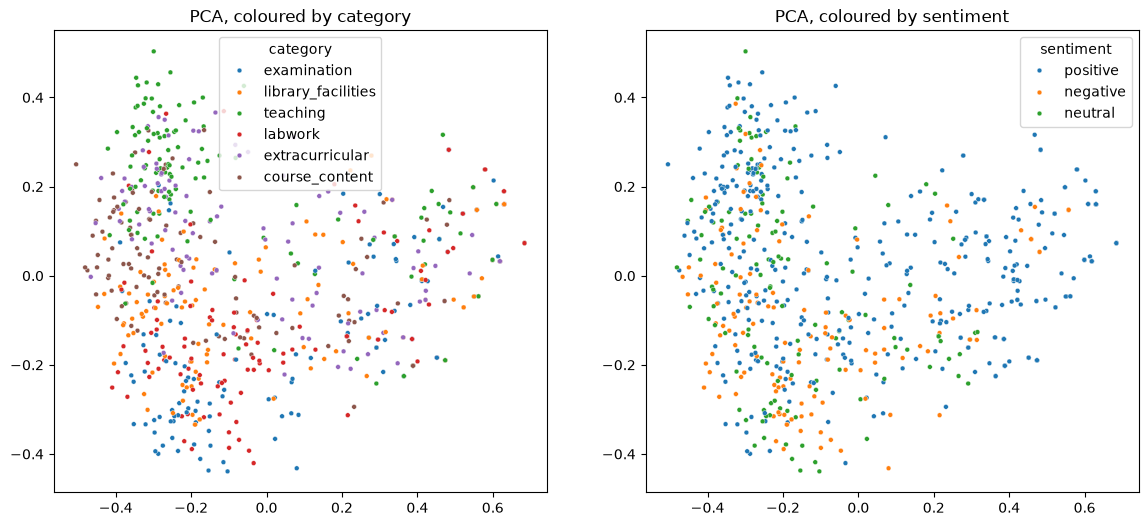

In [27]:
plot_2d(PCA(n_components=2, random_state=42).fit_transform(E), "PCA", RESULTS / "pca_visualisation.png")

**Result:** PCA shows one overlapping cloud with only rough regions (teaching top-left, labwork and examination lower down) and sentiment mixed everywhere, because 2 linear components keep only about 19% of the variance, the same reason `pca=2` clustered worst in 6a.

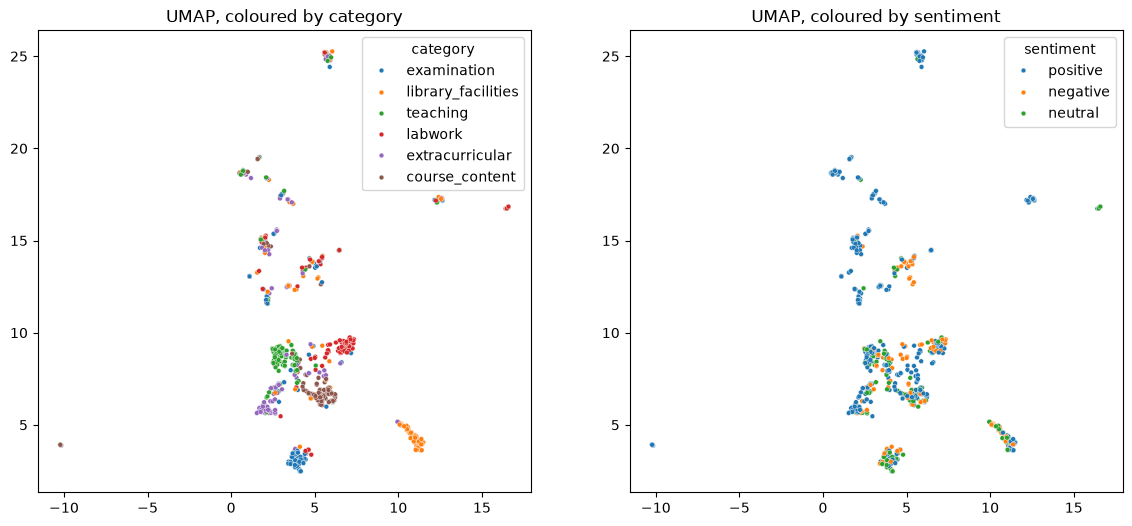

In [28]:
plot_2d(umap.UMAP(n_neighbors=15, metric="cosine", random_state=42).fit_transform(E), "UMAP", RESULTS / "umap_visualisation.png")

**Result:** UMAP shows tight islands, mostly one colour each by category (labwork, examination, teaching, course content, library) but mixed by sentiment, plus small mixed-category islands that match the generic short-comment clusters in 8a, and the islands look far more separated than the low silhouette (0.19 in the full space) says they really are.

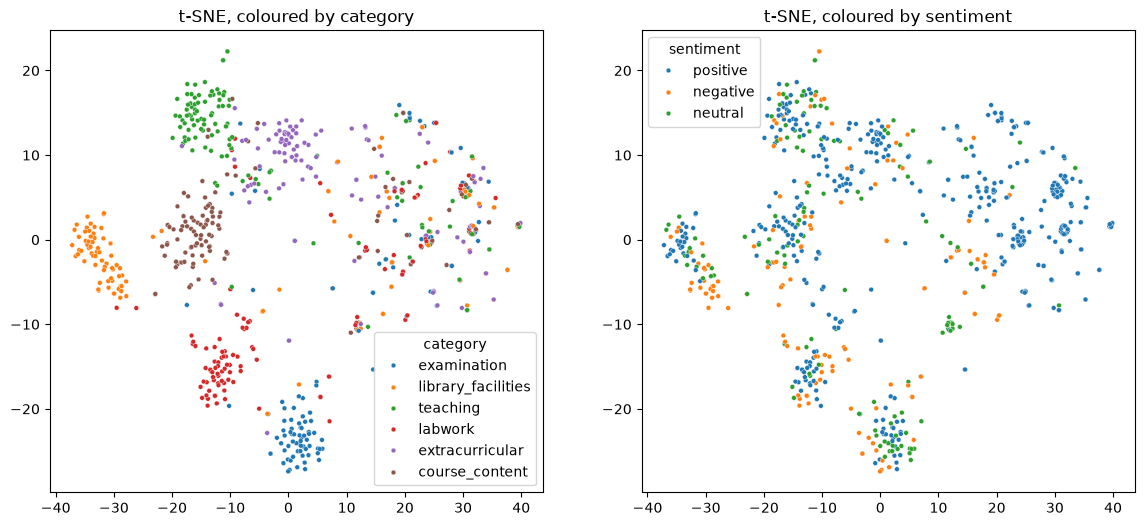

In [29]:
plot_2d(TSNE(perplexity=30, metric="cosine", random_state=42).fit_transform(E), "t-SNE")

**Result:** t-SNE shows the same picture as UMAP (separate groups for each category, with sentiment mixed inside them, plus a scattered right-hand region of mixed categories with small tight knots that are likely repeated generic comments), and two different methods agreeing suggests the topic structure is real rather than an artefact of one method.

## 10. Save outputs

In [30]:
df[["text", "category", "sentiment", "tfidf_cluster", "pca_kmeans_cluster", "umap_hdbscan_cluster"]].to_csv(
    RESULTS / "embedding_clusters.csv", index=False
)

metrics = pd.DataFrame(model_rows + baseline_rows + pca_rows + umap_rows).round(3)
metrics.to_csv(RESULTS / "cluster_metrics.csv", index=False)

In [31]:
report = f"""# Clustering Comparison

Embedding model: {MODEL}

## Chosen configurations

{comparison.to_string(index=False)}

## All runs

{metrics.to_string(index=False)}

## Answers

(fill in from the notebook)
"""

(RESULTS / "clustering_comparison.md").write_text(report)

3817

**Result:** `3824` is the number of characters written to `results/clustering_comparison.md`; with `embedding_clusters.csv` (each comment's cluster under all three methods) and `cluster_metrics.csv` (all 23 runs), it records the Day 3 results for Day 4, but its "Answers" section is still a placeholder until you fill in the questions below.